<a href="https://colab.research.google.com/github/GavrilLaura/PMP-2026/blob/main/Lab07/pmp_tema6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Tema 6 – Laboratorul 7**
##**Inferenţă Bayesiană şi simulare probabilistică**

### Exercițiul 1

**a)** $Y \mid \theta \sim \text{Bin}(50, \theta)$, $\quad P(Y = y \mid \theta) = \binom{50}{y}\theta^{y}(1-\theta)^{50-y}$

**b)** $p(\theta \mid y) \propto \theta^{y}(1-\theta)^{50-y}\cdot\theta^{2-1}(1-\theta)^{18-1} = \theta^{10-1}(1-\theta)^{60-1}$

Deci $\theta \mid Y = 8 \sim \text{Beta}(2 + 8,\ 18 + 50 - 8) = \text{Beta}(10, 60)$ (conjugare Beta–Binomial: posteriorul are aceeași formă ca priorul).

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

alpha_prior = 2
beta_prior = 18
n = 50
y = 8

# b) posteriorul prin conjugare
alpha_post = alpha_prior + y
beta_post = beta_prior + n - y
print("Posterior: Beta(", alpha_post, ",", beta_post, ")")

# c) estimari
mle = y / n
map_est = (alpha_post - 1) / (alpha_post + beta_post - 2)
media_post = alpha_post / (alpha_post + beta_post)

print("MLE   =", round(mle, 4))
print("MAP   =", round(map_est, 4))
print("Media =", round(media_post, 4))

Posterior: Beta( 10 , 60 )
MLE   = 0.16
MAP   = 0.1324
Media = 0.1429


**c)** MLE = 8/50 = 0.16, MAP = 9/68 ≈ 0.132, media a posteriori = 10/70 ≈ 0.143.
MLE folosește doar datele. MAP și media combină datele cu priorul (media priorului 0.1), deci sunt trase spre 0.1: MLE > media > MAP.

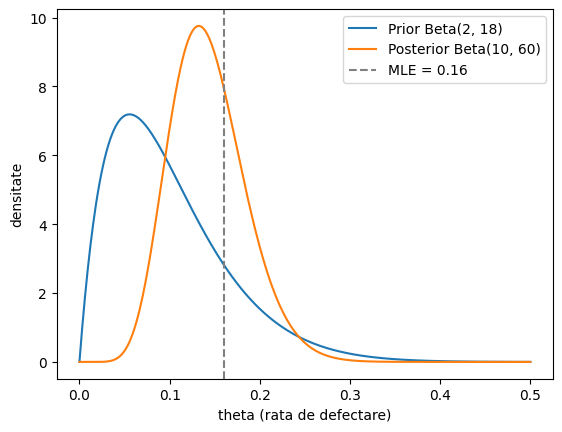

In [2]:
# d) prior si posterior pe acelasi grafic
prior = stats.beta(alpha_prior, beta_prior)
posterior = stats.beta(alpha_post, beta_post)

x = np.linspace(0, 0.5, 500)
plt.plot(x, prior.pdf(x), label="Prior Beta(2, 18)")
plt.plot(x, posterior.pdf(x), label="Posterior Beta(10, 60)")
plt.axvline(mle, color="gray", linestyle="--", label="MLE = 0.16")
plt.xlabel("theta (rata de defectare)")
plt.ylabel("densitate")
plt.legend()
plt.savefig("prior_posterior.png")
plt.show()

**d)** Posteriorul este deplasat spre dreapta față de prior (datele arată 16% defecte, mai mult decât 10% cât credeam) și este mult mai îngust: după 50 de teste suntem mai siguri pe valoarea lui θ.

In [3]:
# e) interval credibil central de 95%
interval = posterior.interval(0.95)
print("Interval credibil 95%: [", round(interval[0], 4), ",", round(interval[1], 4), "]")

# f) P(theta < 0.10 | Y = 8)
p_sub_10 = posterior.cdf(0.10)
print("P(theta < 0.10 | Y = 8) =", round(p_sub_10, 4))
print("P(theta < 0.10) a priori =", round(prior.cdf(0.10), 4))

Interval credibil 95%: [ 0.0717 , 0.2332 ]
P(theta < 0.10 | Y = 8) = 0.1484
P(theta < 0.10) a priori = 0.5797


**e)** Cu probabilitate 95% (condiționat de model și date), rata de defectare este între ≈ 7.2% și ≈ 23.3%.

**f)** P(θ < 0.10 | Y = 8) ≈ 0.148. A priori era ≈ 0.58, dar datele au scăzut-o mult. Datele **nu** susțin cerința ca rata de defectare să fie sub 10%: e mult mai probabil să fie peste.

In [4]:
# g) P(X = 0 | Y = 8) = integrala din (1 - theta)^10 * p(theta | y)
from scipy.integrate import quad

def functie(theta):
    return (1 - theta) ** 10 * posterior.pdf(theta)

p_niciun_defect, eroare = quad(functie, 0, 1)
print("P(X = 0 | Y = 8) (integrala numerica) =", round(p_niciun_defect, 4))

# verificare cu formula exacta: produs de (beta + k) / (alpha + beta + k), k = 0..9
p_exact = 1
for k in range(10):
    p_exact = p_exact * (beta_post + k) / (alpha_post + beta_post + k)
print("P(X = 0 | Y = 8) (formula exacta)     =", round(p_exact, 4))

P(X = 0 | Y = 8) (integrala numerica) = 0.236
P(X = 0 | Y = 8) (formula exacta)     = 0.236


**g)** P(X = 0 | Y = 8) ≈ 0.236. Probabilitatea predictivă ține cont de incertitudinea asupra lui θ (mediază peste toate valorile posibile), nu folosește doar o singură estimare.

### Exercițiul 2

In [5]:
# a) Simularea unei ore (timpii sunt in minute)
import numpy as np

def simuleaza_o_ora(alfa, lam=20, medie_plata=2):
    # momentele sosirilor: timpul dintre sosiri este Exp cu media 60/lam minute
    sosiri = []
    t = np.random.exponential(scale=60 / lam)
    while t <= 60:
        sosiri.append(t)
        t = t + np.random.exponential(scale=60 / lam)

    casa_libera = 0          # cand se elibereaza casa
    bucatarie_libera = 0     # cand se elibereaza statia de gatit
    timpi_totali = []
    timpi_asteptare = []

    for sosire in sosiri:
        plata = np.random.exponential(scale=medie_plata)
        preparare = np.random.exponential(scale=alfa)

        # coada 1: casa
        start_plata = max(sosire, casa_libera)
        sfarsit_plata = start_plata + plata
        casa_libera = sfarsit_plata

        # coada 2: statia de gatit
        start_preparare = max(sfarsit_plata, bucatarie_libera)
        sfarsit_preparare = start_preparare + preparare
        bucatarie_libera = sfarsit_preparare

        timp_total = sfarsit_preparare - sosire
        timpi_totali.append(timp_total)
        timpi_asteptare.append(timp_total - plata - preparare)

    return timpi_totali, timpi_asteptare

np.random.seed(42)
timpi, asteptari = simuleaza_o_ora(alfa=1.0)
print("Clienti in ora simulata:", len(timpi))
print("Timpul maxim pana la mancare:", round(max(timpi), 2), "minute")

Clienti in ora simulata: 23
Timpul maxim pana la mancare: 17.05 minute


**a)** Ținem minte momentul în care se eliberează casa și momentul în care se eliberează stația de gătit. Fiecare client începe plata la max(sosire, casa liberă) și prepararea la max(sfârșit plată, stația liberă), în ordinea sosirii (FIFO). Primește mâncarea la sfârșitul preparării.

alfa = 0.1  P = 0.8105
alfa = 0.2  P = 0.799
alfa = 0.3  P = 0.809
alfa = 0.4  P = 0.799
alfa = 0.5  P = 0.7845
alfa = 0.6  P = 0.7835
alfa = 0.7  P = 0.7615
alfa = 0.8  P = 0.7635
alfa = 0.9  P = 0.734
alfa = 1.0  P = 0.7345
alfa = 1.1  P = 0.7315
alfa = 1.2  P = 0.6945
alfa = 1.3  P = 0.676
alfa = 1.4  P = 0.6435
alfa = 1.5  P = 0.62
alfa = 1.6  P = 0.6005
alfa = 1.7  P = 0.58
alfa = 1.8  P = 0.4965
alfa = 1.9  P = 0.498
alfa = 2.0  P = 0.46
alfa = 2.1  P = 0.404
alfa = 2.2  P = 0.366
alfa = 2.3  P = 0.337
alfa = 2.4  P = 0.317
alfa = 2.5  P = 0.2705
alfa = 2.6  P = 0.261
alfa = 2.7  P = 0.236
alfa = 2.8  P = 0.1935
alfa = 2.9  P = 0.1715
alfa = 3.0  P = 0.146
Nicio valoare a lui alfa nu atinge 95%.
alfa aproape 0: 0.8015


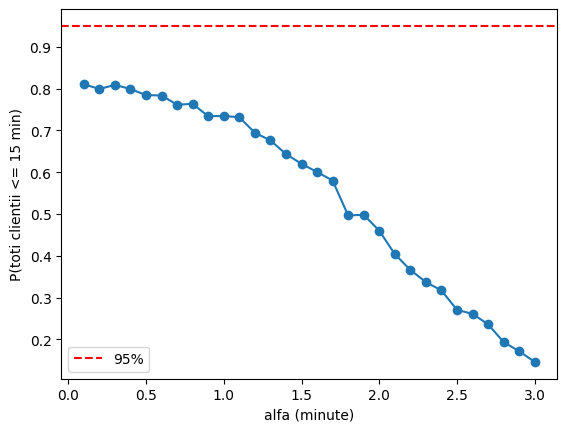

In [6]:
# b) Probabilitatea ca TOTI clientii dintr-o ora sa fie serviti in max. 15 minute
def prob_toti_sub_15(alfa, nr_simulari):
    reusite = 0
    for s in range(nr_simulari):
        timpi, asteptari = simuleaza_o_ora(alfa)
        toti_ok = True
        for timp in timpi:
            if timp > 15:
                toti_ok = False
        if toti_ok:
            reusite = reusite + 1
    return reusite / nr_simulari

np.random.seed(42)
nr_simulari = 2000
valori_alfa = []
probabilitati = []
alfa_maxim = None

alfa = 0.1
while alfa <= 3.0:
    p = prob_toti_sub_15(alfa, nr_simulari)
    valori_alfa.append(alfa)
    probabilitati.append(p)
    print("alfa =", alfa, " P =", p)
    if p >= 0.95:
        alfa_maxim = alfa
    alfa = round(alfa + 0.1, 1)

if alfa_maxim is None:
    print("Nicio valoare a lui alfa nu atinge 95%.")
else:
    print("Cea mai mare alfa cu P >= 0.95:", alfa_maxim)

# limita: preparare practic instantanee (doar casa conteaza)
print("alfa aproape 0:", prob_toti_sub_15(0.0001, nr_simulari))

import matplotlib.pyplot as plt
plt.plot(valori_alfa, probabilitati, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95%")
plt.xlabel("alfa (minute)")
plt.ylabel("P(toti clientii <= 15 min)")
plt.legend()
plt.savefig("probabilitate_alfa.png")
plt.show()

**b)** Probabilitatea scade pe măsură ce α crește, dar chiar pentru α ≈ 0 (preparare instantanee) este doar ≈ 0.81. Deci, cu parametrii dați, **nicio valoare a lui α nu asigură 95%**.

Motivul este casa: sosesc în medie 20 de clienți pe oră (unul la 3 minute), iar plata durează în medie 2 minute, deci casa este ocupată ~67% din timp. Din cauza variabilității timpilor exponențiali se formează uneori cozi, iar într-o oră cu ~20 de clienți este destul de probabil ca măcar unul să aștepte peste 15 minute. Ca să atingem 95%, ar trebui redus timpul de plată (de ex. o a doua casă), nu doar timpul de preparare.

In [7]:
# c) Timpul mediu pana la mancare si timpul mediu de asteptare, pentru cateva valori ale lui alfa
np.random.seed(42)
for alfa in [0.5, 1.0, 2.0]:
    toti_timpii = []
    toate_asteptarile = []
    for s in range(nr_simulari):
        timpi, asteptari = simuleaza_o_ora(alfa)
        for v in timpi:
            toti_timpii.append(v)
        for v in asteptari:
            toate_asteptarile.append(v)
    print("alfa =", alfa,
          " timp mediu pana la mancare =", round(np.mean(toti_timpii), 2), "min",
          " asteptare medie =", round(np.mean(toate_asteptarile), 2), "min")

alfa = 0.5  timp mediu pana la mancare = 5.52 min  asteptare medie = 3.01 min
alfa = 1.0  timp mediu pana la mancare = 6.43 min  asteptare medie = 3.42 min
alfa = 2.0  timp mediu pana la mancare = 9.14 min  asteptare medie = 5.17 min


**c)** Deoarece nu există α care să atingă 95%, am calculat timpii medii pentru câteva valori ale lui α. De exemplu, pentru α = 1 minut, un client așteaptă în medie ≈ 6.4 minute până primește mâncarea, din care ≈ 3.4 minute sunt așteptare efectivă la cozi.

**d)** Am folosit 2000 de simulări pentru fiecare valoare a lui α, sămânța 42 și o căutare pe grilă α = 0.1, 0.2, …, 3.0. Estimările variază de la o rulare la alta (cu altă sămânță) pentru că sunt frecvențe din eșantioane aleatoare; eroarea scade aproximativ ca 1/√(nr. simulări). Pentru 2000 de simulări, eroarea este de ordinul ±0.01.